In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
from contextlib import redirect_stdout, redirect_stderr
import csv
import json
import pickle
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pytket import Circuit
from pytket.circuit.display import render_circuit_jupyter
from pytket.qasm import circuit_from_qasm

# Resolve the same folders whether the kernel starts here or at the repository root.
REPO_ROOT = next(
    parent for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (parent / "python/offline_helix_compiler").is_dir()
)
INPUT_DIR = REPO_ROOT / "notebooks/input"
RESULTS_DIR = REPO_ROOT / "notebooks/results"
INPUT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(REPO_ROOT.parent / "ReTrace"))
sys.path.insert(0, str(REPO_ROOT / "notebooks"))
from architecture_comparison_artifacts import (
    artifact_name, start_run, save_run, load_runs, render_comparison_pdf,
)


In [2]:
# Select one circuit file from input/.
# .json: a pytket Circuit.to_dict() document, or a dictionary containing circuits.
# .qasm: an OpenQASM 2 circuit.
# .pkl / .pickle: a pytket or Qiskit circuit, or a dictionary of circuits.
# For dictionaries, choose e.g. "raw circuit" or "optimized circuit" below.
# Only load pickle files from sources you trust.
# INPUT_FILE = INPUT_DIR / "h2_1qubit_qpe_phase_7.pkl"
# INPUT_FILE = INPUT_DIR / "qsvt_90fs.json"
INPUT_FILE = INPUT_DIR / "ham1_circ.pickle"
CIRCUIT_KEY = "optimized circuit"  # Ignored for a file containing a single circuit.

# Run controls: False skips compilation, its plots/checks, and all compiled cases.
RUN_HELIX_COMPILER = True
SURFACE_CODE_DISTANCE = 5  # Shared by standard surface and surface pFT RZ.
# ReTrace currently rigorously simulates pFT RZ injection only at distance 3.
COLOR_CODE_DISTANCE = 5  # ReTrace supports 3, 5, 7, and 9.
PHYSICAL_QUBIT_PRESETS = {"HELIOS": 98, "SOL": 198, "APOLLO": 1500}
HARDWARE_PRESET = "SOL"
MODEL_LABEL = HARDWARE_PRESET.title()
RETRACE_OPTIONS = {
    "physical_qubits": PHYSICAL_QUBIT_PRESETS[HARDWARE_PRESET],
    "synthesis_accuracy": 1e-2,
    "num_samples": 1,
    "seed": 43,
    "seed_increment": True,
    "demand_factor": 1,
    "demand_ramping": None,
    "allow_jumping": True,
    "perform_ec_on_resource_states": False,
    "careful_alloc": True,
    "debug": False,
    "space_optimized": True,
}
# These distances apply to standalone surface/color codes; hybrid resources stay d3.


def as_pytket(value):
    from qiskit import QuantumCircuit
    from pytket.extensions.qiskit import qiskit_to_tk

    if isinstance(value, Circuit):
        return value.copy()
    if isinstance(value, QuantumCircuit):
        return qiskit_to_tk(value)
    if isinstance(value, dict) and {"commands", "qubits"}.issubset(value):
        return Circuit.from_dict(value)
    raise TypeError("Expected a pytket/Qiskit circuit or a pytket circuit dictionary.")


def load_circuit(path, circuit_key=None):
    path = Path(path)
    if not path.is_file():
        available = ", ".join(p.name for p in sorted(INPUT_DIR.iterdir()) if p.is_file())
        raise FileNotFoundError(f"{path} does not exist. Files in input/: {available}")
    suffix = path.suffix.lower()
    if suffix == ".qasm":
        return circuit_from_qasm(str(path)), None
    if suffix == ".json":
        payload = json.loads(path.read_text())
    elif suffix in {".pkl", ".pickle"}:
        with path.open("rb") as stream:
            payload = pickle.load(stream)
    else:
        raise ValueError("Supported file types: .json, .qasm, .pkl, .pickle")
    try:
        return as_pytket(payload), None
    except TypeError:
        if not isinstance(payload, dict):
            raise
    candidates = {}
    for key, value in payload.items():
        try:
            candidates[key] = as_pytket(value)
        except TypeError:
            continue
    if circuit_key in candidates:
        return candidates[circuit_key], circuit_key
    if len(candidates) == 1:
        key, circuit = next(iter(candidates.items()))
        return circuit, key
    raise ValueError(f"Set CIRCUIT_KEY to one of these circuit entries: {list(candidates)}")


source, selected_key = load_circuit(INPUT_FILE, CIRCUIT_KEY)
input_circuit = source.copy()  # Keep the original for the gate-count report.
RUN_DIR = RESULTS_DIR / INPUT_FILE.stem
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(f"Input: {INPUT_FILE}")
if selected_key is not None:
    print(f"Circuit entry: {selected_key}")
print(f"{source.n_qubits} qubits | {source.n_gates} operations | depth {source.depth()}")
print(f"Output directory: {RUN_DIR}")


Input: /Users/regina.finsterholzl/Projects/helix-logical-compiler/notebooks/input/ham1_circ.pickle
Circuit entry: circuit
4 qubits | 9 operations | depth 6
Output directory: /Users/regina.finsterholzl/Projects/helix-logical-compiler/notebooks/results/ham1_circ


In [3]:
# optionally removes reset at the beginning of the circuit
import warnings

# Assumes each qubit starts in |0>; positions refer to the original circuit.
source_dict = source.to_dict()
reset_indices = set()
for index, command_data in enumerate(source_dict["commands"]):
    operation = command_data["op"]
    while operation["type"] == "Conditional":
        operation = operation["conditional"]["op"]
    if operation["type"] == "Reset":
        reset_indices.add(index)

reset_count = len(reset_indices)
print(f"Reset operations before removal: {reset_count}")
qubit_positions = {qubit: 0 for qubit in source.qubits}
kept_commands = []
removed_resets = 0
for index, (command, command_data) in enumerate(
    zip(source.get_commands(), source_dict["commands"], strict=True)
):
    for qubit in command.qubits:
        qubit_positions[qubit] += 1
    if index in reset_indices:
        qubit = command.qubits[0]
        position = qubit_positions[qubit]
        location = f"command {index + 1}, {qubit}, operation {position} on this qubit"
        if position == 1:
            print(f"Removing Reset at {location} (first operation).")
            removed_resets += 1
            continue
        warnings.warn(
            f"Keeping Reset at {location}: not the first operation on this qubit.",
            stacklevel=2,
        )
    kept_commands.append(command_data)

source_dict["commands"] = kept_commands
source = Circuit.from_dict(source_dict)
print(f"Removed {removed_resets} initial reset(s); kept {reset_count - removed_resets} later reset(s).")
source

Reset operations before removal: 0
Removed 0 initial reset(s); kept 0 later reset(s).


[H phase[0]; H phase[1]; H state[0]; qif (phase[1] = 1) CircBox prep[0], state[0]; qif (phase[0] = 1) CircBox prep[0], state[0]; qif (phase[0] = 1) CircBox prep[0], state[0]; CircBox phase[0], phase[1]; Measure phase[0] --> c[0]; Measure phase[1] --> c[1]; ]

In [8]:
render_circuit_jupyter(source)


In [4]:
# Clear any compilation from a previous run before applying the switch.
synthesis = compiled = None
compilation_seconds = None
(RUN_DIR / "source.json").write_text(json.dumps(source.to_dict(), indent=2) + "\n")

if RUN_HELIX_COMPILER:
    from offline_helix_compiler import compile

    started = perf_counter()
    time_limit_seconds = 10
    synthesis = compile(
        source, contextual_mode="aggressive", beam_width=64,
        plans_per_group=4, allocation_candidates=15,
        measurement_lookahead=8, time_limit_seconds=time_limit_seconds,
    )
    compiled = synthesis.to_circuit()
    compilation_seconds = perf_counter() - started
    print(f"Compilation: {compilation_seconds:.2f} s ({time_limit_seconds} s soft search limit)")
    print(f"Packed rotations: {synthesis.data['grouped_rotations']}; "
          f"logical S: {synthesis.data['s_implementations']}")

    (RUN_DIR / "compiled.json").write_text(json.dumps(compiled.to_dict(), indent=2) + "\n")
    with (RUN_DIR / "compiled.pkl").open("wb") as stream:
        pickle.dump(compiled, stream)
    (RUN_DIR / "compilation.json").write_text(json.dumps({
        "wall_seconds": compilation_seconds,
        "qubit_order": [str(qubit) for qubit in synthesis.qubit_order],
        "synthesis": synthesis.data,
    }, indent=2) + "\n")
else:
    print("Helix compilation disabled; only uncompiled ReTrace cases will run.")


Compilation: 10.05 s (10 s soft search limit)
Packed rotations: 42; logical S: 13


In [5]:
if RUN_HELIX_COMPILER and synthesis is not None:
    from offline_helix_compiler import display_block_circuit, render_block_circuit_svg
    from io import BytesIO
    from reportlab.graphics import renderPDF
    from svglib.svglib import svg2rlg

    display_block_circuit(synthesis, zero_input=True)
    svg = render_block_circuit_svg(synthesis, zero_input=True)
    (RUN_DIR / artifact_name("block_circuit", MODEL_LABEL, ".svg")).write_text(svg)
    drawing = svg2rlg(BytesIO(svg.encode("utf-8")))
    renderPDF.drawToFile(drawing, str(RUN_DIR / artifact_name("block_circuit", MODEL_LABEL, ".pdf")))
    print(f"Saved block circuit for {MODEL_LABEL} in {RUN_DIR}")
else:
    print("Block-circuit rendering skipped because Helix compilation is disabled.")


Saved block circuit for Sol in /Users/regina.finsterholzl/Projects/helix-logical-compiler/notebooks/results/ham1_circ


Maximum measured-output probability difference: 1.19e-14


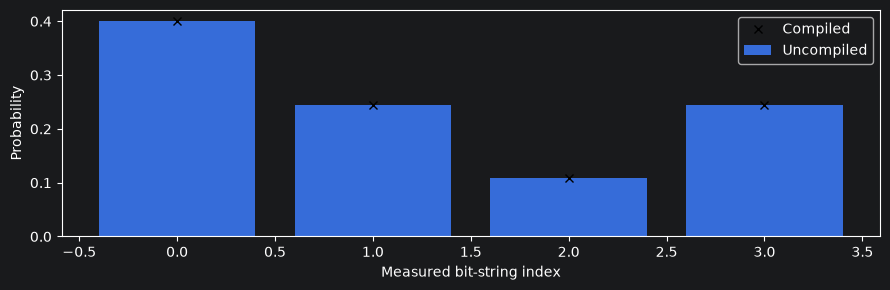

In [6]:
# Exact simulation grows exponentially; enable explicitly for larger circuits.
CHECK_PROBABILITIES = source.n_qubits <= 10 and source.n_bits <= 10
if RUN_HELIX_COMPILER and compiled is not None and CHECK_PROBABILITIES and source.n_bits:
    from offline_helix_compiler.qpe.benchmark import exact_probabilities

    original_probabilities = exact_probabilities(source).reshape(-1)
    compiled_probabilities = exact_probabilities(compiled).reshape(-1)
    assert source.bits == compiled.bits
    np.testing.assert_allclose(original_probabilities, compiled_probabilities, atol=1e-10)
    probability_error = float(np.max(abs(original_probabilities - compiled_probabilities)))
    print(f"Maximum measured-output probability difference: {probability_error:.2e}")
    outcomes = np.arange(len(original_probabilities))
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.bar(outcomes, original_probabilities, label="Uncompiled")
    ax.plot(outcomes, compiled_probabilities, "x", color="black", label="Compiled")
    ax.set(xlabel="Measured bit-string index", ylabel="Probability")
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / artifact_name("output_probabilities", MODEL_LABEL, ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    (RUN_DIR / artifact_name("probability_check", MODEL_LABEL, ".json")).write_text(json.dumps({
        "maximum_difference": probability_error,
        "bits": [str(bit) for bit in source.bits],
    }, indent=2) + "\n")
else:
    print("Probability comparison skipped (no compilation, check disabled, or no measured bits).")


In [7]:
# Gate counts and dimensions of the original circuit, before initial-reset cleanup.
gate_counts = Counter(command.op.type.name for command in input_circuit.get_commands())
source_summary = {
    "qubits": input_circuit.n_qubits,
    "bits": input_circuit.n_bits,
    "operations": input_circuit.n_gates,
    "depth": input_circuit.depth(),
    "gate_counts": dict(sorted(gate_counts.items())),
    "removed_initial_resets": removed_resets,
    "operations_after_reset_cleanup": source.n_gates,
    "depth_after_reset_cleanup": source.depth(),
}
display(Markdown(
    f"**Original circuit:** {input_circuit.n_qubits} qubits, {input_circuit.n_bits} classical bits, "
    f"{input_circuit.n_gates} operations, depth {input_circuit.depth()}. "
    f"Initial resets removed for compilation: {removed_resets}."
))
gate_rows = ["| Gate / operation | Count |", "| --- | ---: |"]
gate_rows += [f"| {gate} | {count} |" for gate, count in sorted(gate_counts.items())]
display(Markdown("\n".join(gate_rows)))
(RUN_DIR / "original_circuit.json").write_text(json.dumps(source_summary, indent=2) + "\n")
with (RUN_DIR / artifact_name("original_gate_counts", MODEL_LABEL, ".csv")).open("w", newline="") as stream:
    writer = csv.writer(stream)
    writer.writerow(["gate", "count"])
    writer.writerows(sorted(gate_counts.items()))


**Original circuit:** 4 qubits, 2 classical bits, 9 operations, depth 6. Initial resets removed for compilation: 0.

| Gate / operation | Count |
| --- | ---: |
| CircBox | 1 |
| H | 3 |
| Measure | 2 |
| QControlBox | 3 |

In [8]:
from offline_helix_compiler.qpe.benchmark import estimate_tts
from pytket import OpType
from pytket.passes import AutoRebase, DecomposeBoxes

# Reporting heuristic only; leave RETRACE_OPTIONS["synthesis_accuracy"] unchanged.
epsilon_report = 1e-6
rotation_counts = {}

def count_rotation_gates(circuit):
    # Expand compound gates on a copy, preserving rotations for counting.
    rotation_types = {OpType.Rx, OpType.Ry, OpType.Rz, OpType.ZZPhase}
    counting_copy = circuit.copy()
    DecomposeBoxes().apply(counting_copy)
    AutoRebase({
        OpType.H, OpType.S, OpType.Sdg, OpType.T, OpType.Tdg,
        OpType.X, OpType.Y, OpType.Z, OpType.CX, *rotation_types,
    }).apply(counting_copy)
    return sum(command.op.type in rotation_types for command in counting_copy.get_commands())

# Toggle an architecture with enabled; remove a variant to skip that run.
ARCHITECTURES = {
    "surface": {"enabled": True, "code_distance": SURFACE_CODE_DISTANCE, "variants": ("uncompiled",)},
    "surface_pft_rz": {"enabled": True, "code_distance": SURFACE_CODE_DISTANCE, "variants": ("uncompiled",)},
    "color": {"enabled": True, "code_distance": COLOR_CODE_DISTANCE, "variants": ("uncompiled",)},
    "helix": {"enabled": True, "variants": ("uncompiled", "compiled")},
    "hybrid_helix_surface": {"enabled": True, "variants": ("uncompiled", "compiled")},
}
# Surface, color, and conventional Helix use Clifford+T synthesis.
# Surface pFT RZ and hybrid retain arbitrary angles. Errors exclude synthesis approximation.
# Measurement and classical-processing costs are omitted by the estimator.

architecture_names = {
    "surface": "Surface d3",
    "surface_pft_rz": "Surface pFT RZ d3",
    "color": "Color d3",
    "helix": "Helix",
    "hybrid_helix_surface": "Helix + surface d3",
}
planned_runs = []
for architecture, config in ARCHITECTURES.items():
    if not config["enabled"]:
        continue
    label = architecture_names[architecture]
    if architecture in {"surface", "color"}:
        label = f"{architecture.title()} d{config['code_distance']}"
    elif architecture == "surface_pft_rz":
        label = f"Surface pFT RZ d{config['code_distance']}"
    for variant in config["variants"]:
        if variant == "compiled" and not RUN_HELIX_COMPILER:
            continue
        if variant not in {"uncompiled", "compiled"}:
            raise ValueError(f"Unknown circuit variant: {variant}")
        if variant == "compiled" and architecture not in {"helix", "hybrid_helix_surface"}:
            raise ValueError("Compiled circuits are compared on Helix and hybrid only.")
        if variant == "compiled" and (compiled is None or synthesis is None):
            raise ValueError("Run the compilation cell before requesting compiled comparisons.")
        planned_runs.append({
            "case": f"{label} — {variant}", "architecture": architecture,
            "variant": variant, "run_id": f"{architecture}_{variant}",
            "code_distance": config.get("code_distance", 3),
        })

# This manifest is saved before the first simulation. Each completed case is
# committed independently, so Interrupt leaves earlier results available.
run_manifest = start_run(
    RUN_DIR, MODEL_LABEL, planned_runs,
    input_file=str(INPUT_FILE), circuit_key=selected_key,
    helix_compiler_enabled=RUN_HELIX_COMPILER,
    hardware_preset=HARDWARE_PRESET, settings=RETRACE_OPTIONS,
    architectures=ARCHITECTURES,
)
for planned in planned_runs:
    name, run_id = planned["case"], planned["run_id"]
    circuit = source if planned["variant"] == "uncompiled" else compiled
    allocation = None if planned["variant"] == "uncompiled" else synthesis.qubit_order
    record = dict(planned)
    print(f"Estimating {name}...", flush=True)
    try:
        log_file = RUN_DIR / artifact_name(run_id, MODEL_LABEL, ".log")
        with log_file.open("w") as log, redirect_stdout(log), redirect_stderr(log):
            if planned["architecture"] not in {"surface_pft_rz", "hybrid_helix_surface"}:
                variant = planned["variant"]
                if variant not in rotation_counts:
                    rotation_counts[variant] = count_rotation_gates(circuit)
                num_rotations = rotation_counts[variant]
                ler_synth = 1 - (1 - epsilon_report) ** num_rotations
                record.update(num_rotations=num_rotations, epsilon_report=epsilon_report, ler_synth=ler_synth)
            scheduler = estimate_tts(
                circuit, allocation, architecture=planned["architecture"],
                code_distance=planned["code_distance"],
                return_scheduler=True, **RETRACE_OPTIONS,
            )
    except Exception as error:
        record.update(status="failed", error=f"{type(error).__name__}: {error}")
        save_run(RUN_DIR, run_manifest, record)
        print(f"  Failed: {record['error']} (see {log_file.name})")
    else:
        estimate = scheduler.extrusion
        record.update(
            status="ok", samples=estimate.num_samples,
            mean_depth=estimate.mean_time_step, std_depth=estimate.std_time_step,
            mean_runtime_s=estimate.mean_real_time, std_runtime_s=estimate.std_real_time,
            mean_error_rate=estimate.mean_error_rate, std_error_rate=estimate.std_error_rate,
            peak_physical_qubits=estimate.max_allocated_exact,
            idling_limit_exceeded=any(scheduler.max_idling_time_exceeded),
        )
        save_run(RUN_DIR, run_manifest, record, estimate)
        print(f"  {estimate.mean_real_time:.3f} s; modeled failure {estimate.mean_error_rate:.3e}")

if not planned_runs:
    print("No architectures selected. Enable at least one entry in ARCHITECTURES.")


Estimating Surface d5 — uncompiled...
  531.990 s; modeled failure 7.931e-04
Estimating Surface pFT RZ d5 — uncompiled...
  Failed: ValueError: Scheduler: no instructions exist in queue, yet instructions remain to be scheduled: Counter({(CNOT, ()): 118, (H, ()): 79, (Teleport_RZ_Plus_State, (0.785398163397,)): 66, (Teleport_RZ_Plus_State, (-0.785398163397,)): 45, (Teleport_RZ_Plus_State, (1.570796326795,)): 30, (Teleport_RZ_Plus_State, (10.995574287564,)): 24, (Teleport_RZ_Plus_State, (2.356194490192,)): 17, (Teleport_RZ_Plus_State, (9.424777960769,)): 12, (Teleport_RZ_Plus_State, (8.639379797372,)): 6, (Teleport_RZ_Plus_State, (11.852646235414,)): 3, (Teleport_RZ_Plus_State, (0.713724378945,)): 3, (Teleport_RZ_Plus_State, (3.14159265359,)): 3, (Teleport_RZ_Plus_State, (11.709298666509,)): 3, (Teleport_RZ_Plus_State, (4.712388980385,)): 3, (Teleport_RZ_Plus_State, (0.85707194785,)): 3, (Teleport_RZ_Plus_State, (10.210176124167,)): 1, (Prep_Z, ()): 0}). (see surface_pft_rz_uncompiled_So

# Architecture comparison — Sol

Input: ham1_circ.pickle; circuit entry: circuit; 198 physical qubits.

| Architecture / circuit | Mean depth ± std | Mean runtime (s) ± std (s) | Mean runtime (min) | Mean runtime (h) | Peak physical qubits | Mean circuit error ± std | Synthesis error heuristic (ε=10⁻⁶) | Idling limit exceeded |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | --- |
| Surface d5 — uncompiled | 17733.00 ± 0.00 | 532 ± 0.000 | 8.87 | 0.1478 | 198 | 7.931e-04 ± 0.000e+00 | 1.200e-04 | No |
| Surface pFT RZ d5 — uncompiled | Failed | — | — | — | — | — | — | — |
| Color d5 — uncompiled | 9639.00 ± 0.00 | 289 ± 0.000 | 4.82 | 0.0803 | 189 | 6.958e-06 ± 0.000e+00 | 1.200e-04 | No |
| Helix — uncompiled | 29857.00 ± 0.00 | 896 ± 0.000 | 14.93 | 0.2488 | 196 | 3.090e-04 ± 0.000e+00 | 1.200e-04 | No |
| Helix — compiled | 15366.00 ± 0.00 | 461 ± 0.000 | 7.68 | 0.1280 | 196 | 1.563e-04 ± 0.000e+00 | 1.290e-04 | No |
| Helix + surface d3 — uncompiled | 10707.00 ± 0.00 | 321 ± 0.000 | 5.35 | 0.0892 | 197 | 1.244e-03 ± 0.000e+00 | — | No |
| Helix + surface d3 — compiled | 7008.00 ± 0.00 | 210 ± 0.000 | 3.50 | 0.0584 | 197 | 1.044e-03 ± 0.000e+00 | — | No |

Synthesis heuristic: 1-(1-10⁻⁶)^N, with N the Rx/Ry/Rz/RZZ count after expanding compound gates on a copy, separately for each circuit variant. This fixed reporting epsilon does not change the synthesis settings or mean error rate. — means no Clifford+T synthesis; Not recorded refers to older saved results.


TTS is runtime per circuit execution. Circuit error excludes synthesis approximation and readout costs.

With one sample, zero standard deviation does not estimate run-to-run variation.

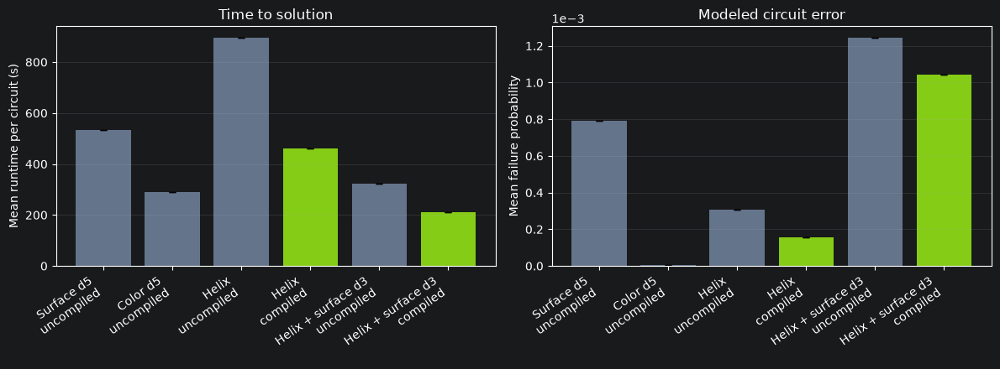

In [9]:
# Evaluate completed runs from disk, including after Interrupt or a kernel restart.
run_manifest, run_records, estimates = load_runs(RUN_DIR, MODEL_LABEL)
saved_options = run_manifest["settings"]
saved_input_name = Path(run_manifest["input_file"]).name
saved_circuit_key = run_manifest["circuit_key"]
comparison_rows = [
    "| Architecture / circuit | Mean depth ± std | Mean runtime (s) ± std (s) | Mean runtime (min) | Mean runtime (h) | Peak physical qubits | Mean circuit error ± std | Synthesis error heuristic (ε=10⁻⁶) | Idling limit exceeded |",
    "| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | --- |",
]
for record in run_records:
    if record["status"] != "ok":
        state = "Pending" if record["status"] == "pending" else "Failed"
        comparison_rows.append(f"| {record['case']} | {state} | — | — | — | — | — | — | — |")
        continue
    mean_runtime_s = record["mean_runtime_s"]
    synthesis_text = "—" if record["architecture"] in {"surface_pft_rz", "hybrid_helix_surface"} else (
        f"{record['ler_synth']:.3e}" if "ler_synth" in record else "Not recorded"
    )
    comparison_rows.append(
        f"| {record['case']} | {record['mean_depth']:.2f} ± {record['std_depth']:.2f} "
        f"| {mean_runtime_s:.0f} ± {record['std_runtime_s']:.3f} "
        f"| {mean_runtime_s / 60:.2f} "
        f"| {mean_runtime_s / 3600:.4f} "
        f"| {record['peak_physical_qubits']} "
        f"| {record['mean_error_rate']:.3e} ± {record['std_error_rate']:.3e} "
        f"| {synthesis_text} "
        f"| {'Yes' if record['idling_limit_exceeded'] else 'No'} |"
    )
comparison_text = (
    f"# Architecture comparison — {MODEL_LABEL}\n\n"
    f"Input: {saved_input_name}; circuit entry: {saved_circuit_key or 'single circuit'}; "
    f"{saved_options['physical_qubits']} physical qubits.\n\n"
    + "\n".join(comparison_rows) + "\n\n"
    + "Synthesis heuristic: 1-(1-10⁻⁶)^N, with N the Rx/Ry/Rz/RZZ count after expanding compound gates on a copy, separately for each circuit variant. "
      "This fixed reporting epsilon does not change the synthesis settings or mean error rate. "
      "— means no Clifford+T synthesis; Not recorded refers to older saved results.\n"
)
display(Markdown(comparison_text))
display(Markdown("TTS is runtime per circuit execution. Circuit error excludes synthesis approximation and readout costs."))
if saved_options["num_samples"] == 1:
    display(Markdown("With one sample, zero standard deviation does not estimate run-to-run variation."))
markdown_file = RUN_DIR / artifact_name("architecture_comparison", MODEL_LABEL, ".md")
markdown_file.write_text(comparison_text)
summary_file = RUN_DIR / artifact_name("architecture_comparison", MODEL_LABEL, ".json")
summary_file.write_text(json.dumps({**run_manifest, "runs": run_records}, indent=2) + "\n")
fields = list(dict.fromkeys(key for record in run_records for key in record))
if fields:
    with (RUN_DIR / artifact_name("architecture_comparison", MODEL_LABEL, ".csv")).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(run_records)
render_comparison_pdf(
    markdown_file, RUN_DIR / "original_circuit.json",
    RUN_DIR / artifact_name("architecture_comparison", MODEL_LABEL, ".pdf"),
    model=MODEL_LABEL, input_file=saved_input_name, circuit_key=saved_circuit_key,
    physical_qubits=saved_options["physical_qubits"],
)

successful = [record for record in run_records if record["status"] == "ok"]
if successful:
    positions = np.arange(len(successful))
    labels = [record["case"].replace(" — ", "\n") for record in successful]
    colors = ["#84cc16" if record["variant"] == "compiled" else "#64748b" for record in successful]
    fig, axes = plt.subplots(1, 2, figsize=(max(12, len(successful) * 2), 4.5))
    for ax, mean_key, std_key, title, ylabel in (
        (axes[0], "mean_runtime_s", "std_runtime_s", "Time to solution", "Mean runtime per circuit (s)"),
        (axes[1], "mean_error_rate", "std_error_rate", "Modeled circuit error", "Mean failure probability"),
    ):
        ax.bar(positions, [record[mean_key] for record in successful],
               yerr=[record[std_key] for record in successful], color=colors, capsize=3)
        ax.set_xticks(positions, labels, rotation=35, ha="right")
        ax.set(title=title, ylabel=ylabel)
        ax.grid(axis="y", alpha=0.2)
    axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    fig.tight_layout()
    fig.savefig(RUN_DIR / artifact_name("architecture_comparison", MODEL_LABEL, ".png"), dpi=150, bbox_inches="tight")
    fig.savefig(RUN_DIR / artifact_name("architecture_comparison_chart", MODEL_LABEL, ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)


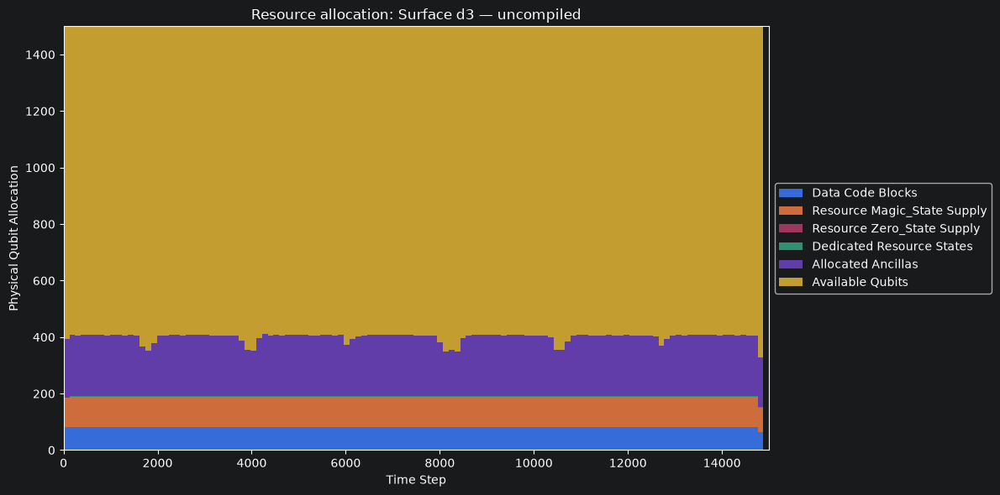

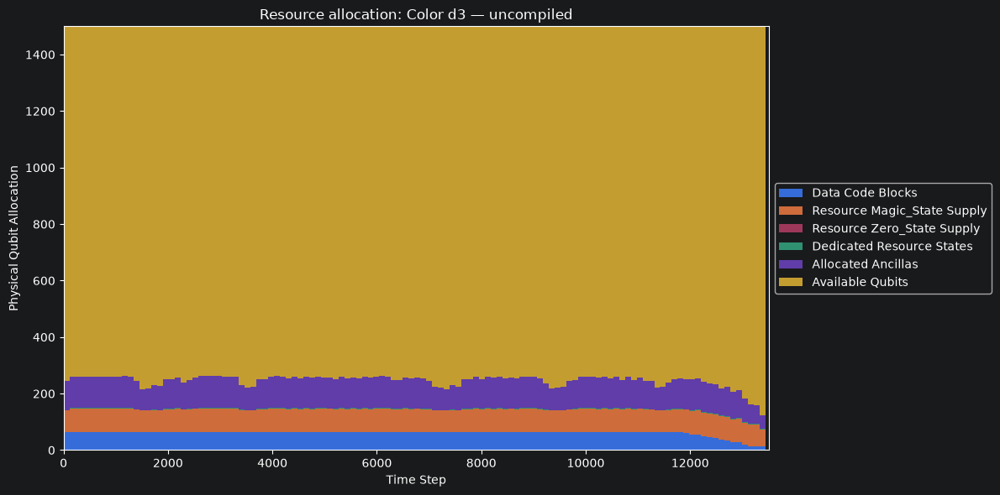

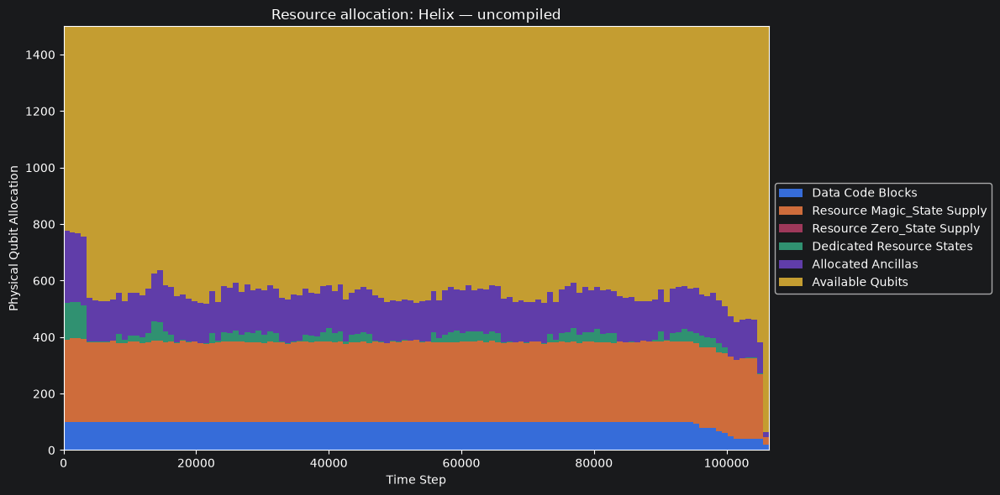

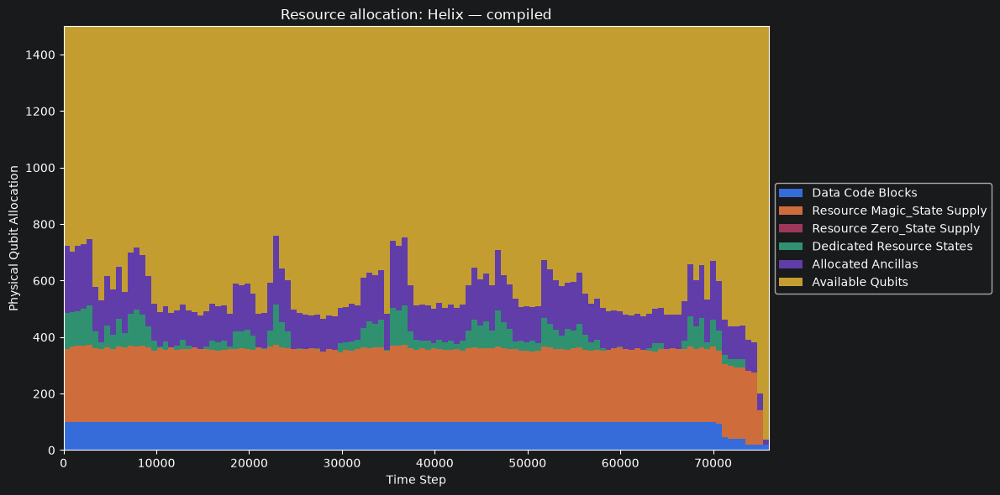

/Users/regina.finsterholzl/Projects/ReTrace/resource_estimator/plotting.py:47: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


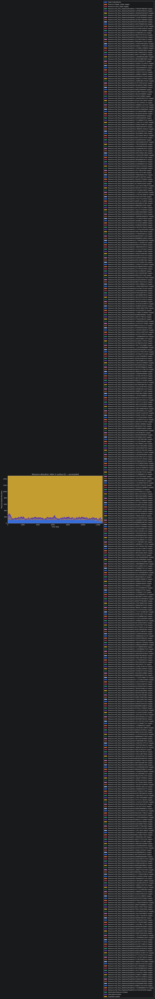




In [18]:
# Resource allocation profiles, as in prototype_ising.
from resource_estimator.codes.csdcode import CSDResourceState
from resource_estimator.plotting import plot_allocation_profiles_stacked_bar

SHOW_ALLOCATION_PROFILES = True
if SHOW_ALLOCATION_PROFILES:
    for record in successful:
        name = record["case"]
        max_steps = max(estimates[name].sample_time_steps)
        allocation_bin_size = max(1, round(max_steps / 120))
        fig, ax = plot_allocation_profiles_stacked_bar(
            estimates[name], title=f"Resource allocation: {name}",
            bin_size=allocation_bin_size,
            resource_state_filter=lambda state: state != CSDResourceState.ZeroECIdleState,
            yscale="linear", ymax=run_manifest["settings"]["physical_qubits"], end=None,
        )
        ax.set_xlim(0, max_steps + allocation_bin_size)
        fig.savefig(RUN_DIR / artifact_name(f"{record['run_id']}_allocation", MODEL_LABEL, ".png"), dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)


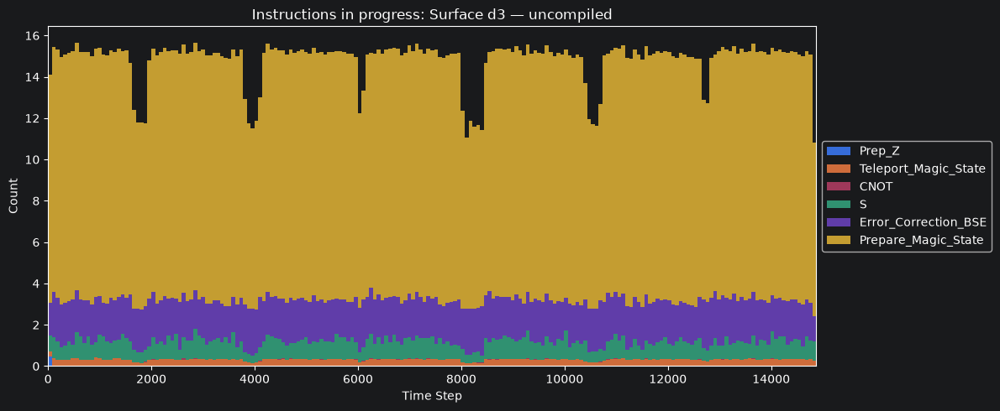

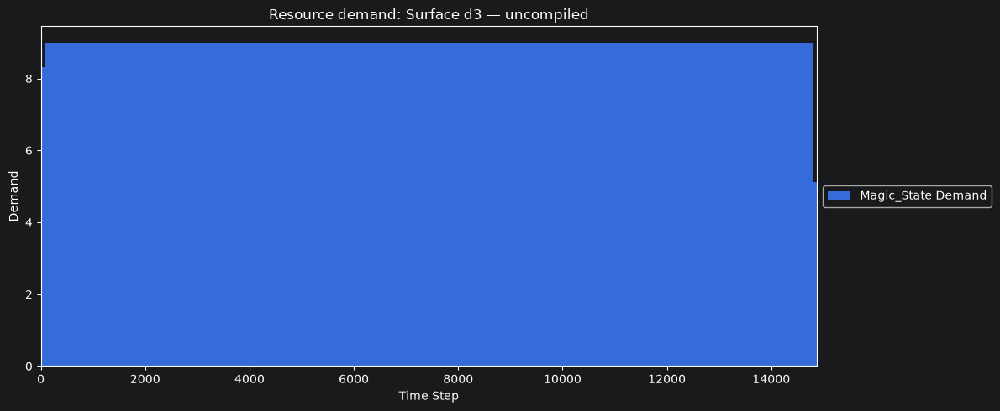

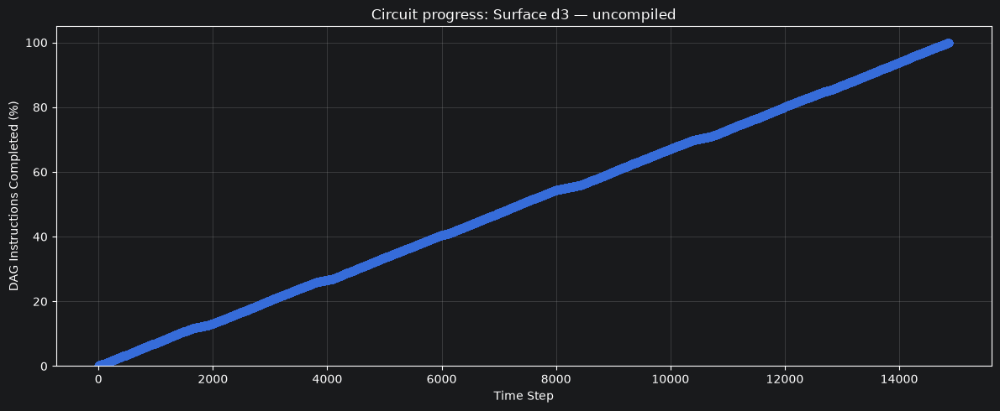

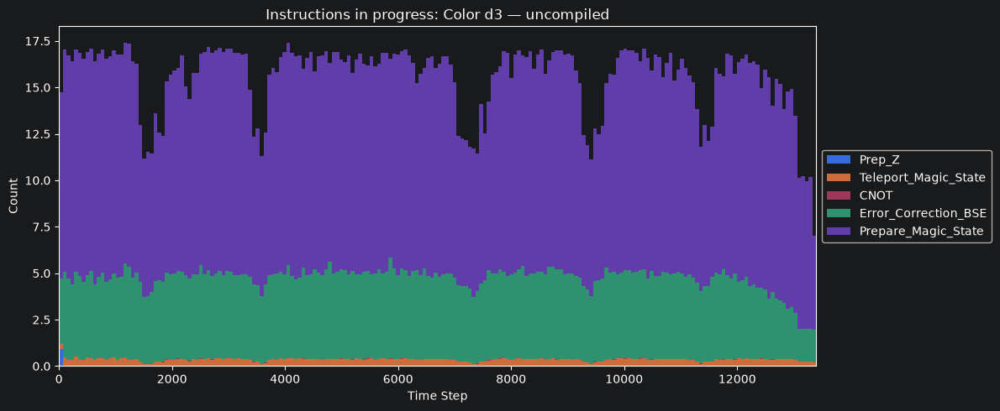

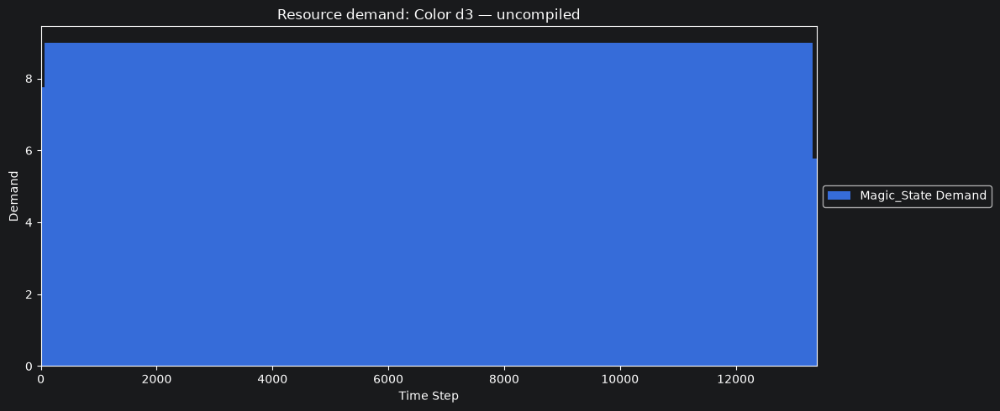

...

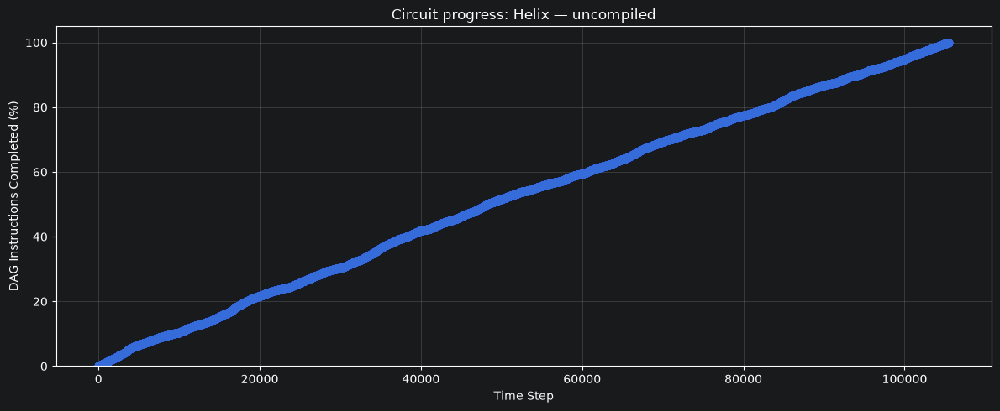

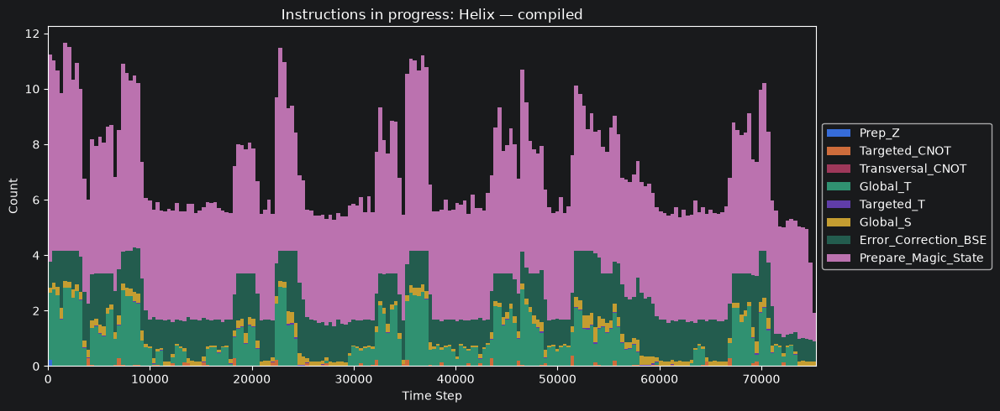

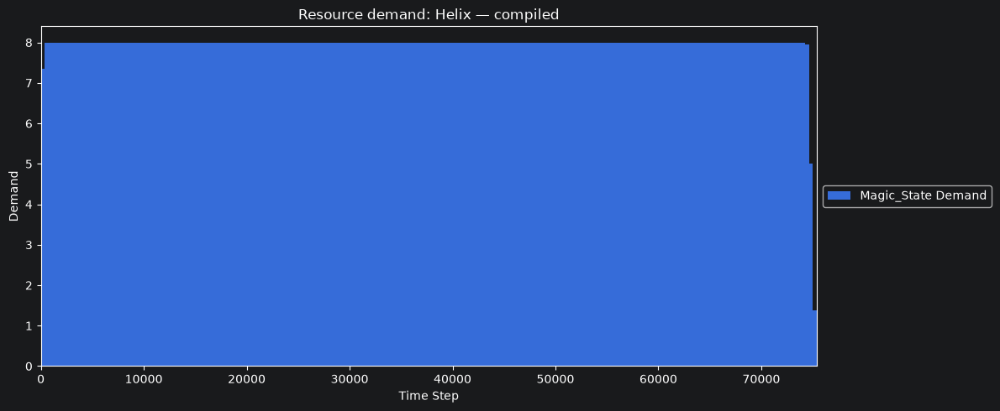

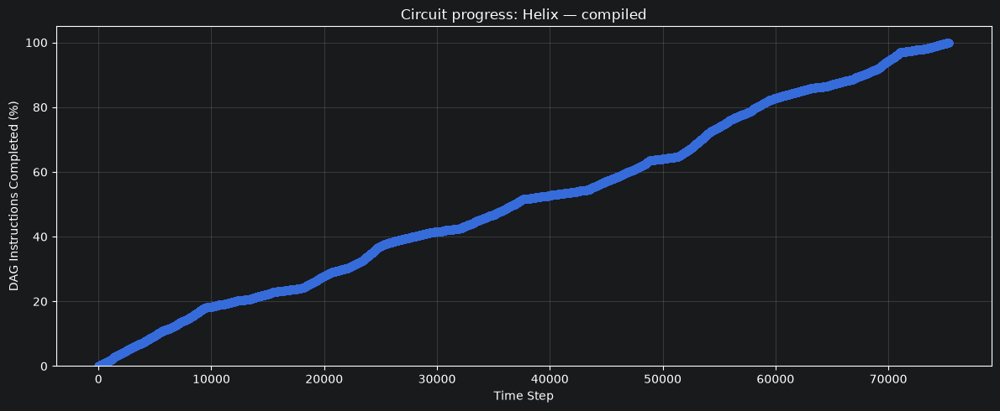

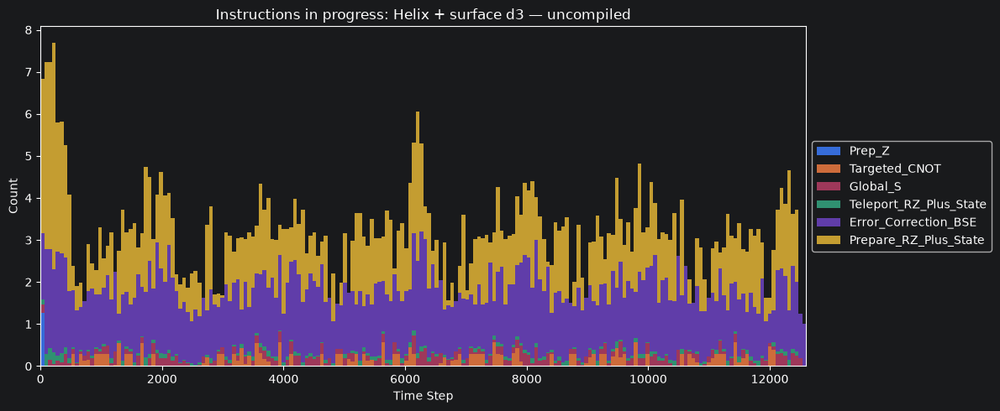

KeyboardInterrupt: 

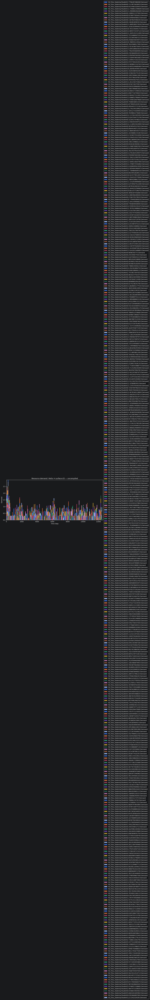

In [19]:
# Instruction activity, resource demand, and circuit progress, as in prototype_ising.
from resource_estimator.plotting import (
    plot_instruction_profiles_stacked_bar,
    plot_resource_demand_stacked_bar,
    plot_dag_progress,
)

SHOW_SCHEDULING_DETAILS = True
if SHOW_SCHEDULING_DETAILS:
    for record in successful:
        name = record["case"]
        estimate = estimates[name]
        instruction_bin_size = max(2, round(max(estimate.sample_time_steps) / 200))
        for plotter, suffix, title in (
            (plot_instruction_profiles_stacked_bar, "instructions", "Instructions in progress"),
            (plot_resource_demand_stacked_bar, "resource_demand", "Resource demand"),
        ):
            fig, ax = plotter(estimate, title=f"{title}: {name}",
                              bin_size=instruction_bin_size, yscale="linear", end=None)
            fig.savefig(RUN_DIR / artifact_name(f"{record['run_id']}_{suffix}", MODEL_LABEL, ".png"), dpi=150, bbox_inches="tight")
            plt.show()
            plt.close(fig)
        fig, ax = plot_dag_progress(estimate, title=f"Circuit progress: {name}", stride=1, end=None)
        fig.savefig(RUN_DIR / artifact_name(f"{record['run_id']}_progress", MODEL_LABEL, ".png"), dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
